# 03 · Nihai model, kilitli test tahminleri ve bağımsız test
**YSA Vize Projesi – Elif Öztürk (244329059)**

**Bölüm A** (test etiketleri kullanılmaz): `final_selection.json`'daki konfigürasyon tam development üzerinde 3 önceden belirlenmiş seed ile eğitilir; etiketsiz tahminler `test_predictions_locked.csv` dosyasına yazılır. Bu dosya GitHub'da ayrı bir commit ile kilitlenmiştir (`kilit/` klasörü, commit `e1dde65`).

**Kilit kontrolü:** Yeniden üretilen tahminler GitHub'daki kilitli dosyayla karşılaştırılır.

**Bölüm B:** Test etiketleri yalnızca bundan sonra okunur: metrikler, seed kararlılığı, bootstrap %95 GA, confusion matrix, ROC/PR, hata analizi, rapor tabloları ve şekilleri.

In [ ]:
# Veri dosyası çalışma klasöründe yoksa resmi kaynaktan (UCI) indirilir.
import os, io, zipfile, urllib.request
if not os.path.exists("bank-additional.csv"):
    dis_zip = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(
        "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip").read()))
    ic_zip = zipfile.ZipFile(io.BytesIO(dis_zip.read("bank-additional.zip")))
    open("bank-additional.csv", "wb").write(ic_zip.read("bank-additional/bank-additional.csv"))
print("bank-additional.csv hazır")

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1) Seed
SEED = 29059 + 2026   # = 31085

# 2) Veriyi oku
df = pd.read_csv("bank-additional.csv", sep=";")
print("Boyut:", df.shape)
print(df["y"].value_counts())

# 3) duration sütununu çıkar
df = df.drop(columns=["duration"])

# 4) Hedefi 0/1 yap
y = (df["y"] == "yes").astype(int)

# 5) %80 development / %20 test, stratified
dev, test = train_test_split(df, test_size=0.2, stratify=y, random_state=SEED)

print("Development:", len(dev), "| Test:", len(test))
print("Development pozitif oran:", round((dev["y"] == "yes").mean(), 4))
print("Test pozitif oran:       ", round((test["y"] == "yes").mean(), 4))

Boyut: (4119, 21)
y
no     3668
yes     451
Name: count, dtype: int64
Development: 3295 | Test: 824
Development pozitif oran: 0.1096
Test pozitif oran:        0.1092


In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

num_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate",
            "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]

# Bölünmenin 01_eda.ipynb'dekiyle aynı olduğunu doğrula
if os.path.exists("dataset_split.csv"):
    kayitli = pd.read_csv("dataset_split.csv")
    assert set(kayitli.loc[kayitli["set"] == "test", "orig_index"]) == set(test.index), "Bölünme farklı!"
    print("Bölünme dataset_split.csv ile aynı ✅")

## Önceki notebook'tan gelen dosyalar
`02_nested_cv.ipynb` aynı oturumda çalıştırılmadıysa `final_selection.json` ve diğer sonuç dosyaları Drive'dan alınır.

In [ ]:
from google.colab import drive
import shutil
drive.mount("/content/drive")
KLASOR = "/content/drive/MyDrive/YSA_Vize_cikti"
for f in ["final_selection.json", "inner_cv_results.csv", "outer_cv_results.csv"]:
    if not os.path.exists(f):
        shutil.copy(f"{KLASOR}/{f}", f); print("Drive'dan alındı:", f)

## Gerekli fonksiyonlar (02 ile aynı)

In [ ]:
def ozellikleri_hazirla(df):
    X = df.drop(columns=["y"]).copy()
    X["pdays_never"] = (X["pdays"] == 999).astype(float)          # yeni 0/1 sütun
    X["pdays"] = X["pdays"].where(X["pdays"] != 999, np.nan)       # 999 -> boş
    return X

X_dev = ozellikleri_hazirla(dev).reset_index(drop=True)
y_dev = (dev["y"] == "yes").astype(int).to_numpy()
print(X_dev.shape)
print(X_dev[["pdays", "pdays_never"]].head())

(3295, 20)
   pdays  pdays_never
0    NaN          1.0
1    NaN          1.0
2    NaN          1.0
3    NaN          1.0
4    NaN          1.0


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder

class YuzdelikKirpici(BaseEstimator, TransformerMixin):
    """Alt/üst eşikleri eğitim verisinden öğrenir (%1 ve %99), sonra uçları o eşiklere çeker."""
    def __init__(self, alt=1, ust=99):
        self.alt, self.ust = alt, ust
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanpercentile(X, self.alt, axis=0)
        self.hi_ = np.nanpercentile(X, self.ust, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

OLCEKLER = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}

def on_isleme_yap(olcek="standard", kirp=False):
    sayisal_adimlar = [("doldur", SimpleImputer(strategy="median"))]
    if kirp:
        sayisal_adimlar.append(("kirp", YuzdelikKirpici()))
    sayisal_adimlar.append(("olcekle", OLCEKLER[olcek]()))

    return ColumnTransformer([
        ("sayisal", Pipeline(sayisal_adimlar), num_cols),
        ("bayrak", "passthrough", ["pdays_never"]),
        ("kategorik", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

In [ ]:
import torch
import torch.nn as nn
import time

torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)

class MLP(nn.Module):
    def __init__(self, girdi, gizli=(32,), aktivasyon="relu", dropout=0.0):
        super().__init__()
        Akt = {"relu": nn.ReLU, "tanh": nn.Tanh}[aktivasyon]
        katmanlar, onceki = [], girdi
        for h in gizli:
            katmanlar += [nn.Linear(onceki, h), Akt()]
            if dropout > 0:
                katmanlar.append(nn.Dropout(dropout))
            onceki = h
        katmanlar.append(nn.Linear(onceki, 1))      # tek çıkış: logit
        self.ag = nn.Sequential(*katmanlar)

    def forward(self, x):
        return self.ag(x).squeeze(-1)

m = MLP(62, (32,))
print(m)
print("Parametre sayısı:", sum(p.numel() for p in m.parameters()))

MLP(
  (ag): Sequential(
    (0): Linear(in_features=62, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parametre sayısı: 2049


In [ ]:
VARSAYILAN = dict(optimizer="adamw", gizli=(32,), aktivasyon="relu", lr=1e-3,
                  weight_decay=1e-4, batch=64, dropout=0.0, olcek="standard",
                  kirp=False, scheduler=True)

def mlp_egit(ayar, X, y, seed=SEED + 2, es_seed=SEED + 6, max_epoch=150, sabir=15):
    a = {**VARSAYILAN, **ayar}
    t0 = time.perf_counter()

    # 1) %85 fit / %15 early-stop alt kümesi
    idx = np.arange(len(y))
    fit_idx, es_idx = train_test_split(idx, test_size=0.15, stratify=y, random_state=es_seed)

    # 2) Ön işleme SADECE fit alt kümesinde öğrenilir
    on = on_isleme_yap(a["olcek"], a["kirp"])
    Z_fit = on.fit_transform(X.iloc[fit_idx])
    Z_es = on.transform(X.iloc[es_idx])

    Xt = torch.tensor(Z_fit, dtype=torch.float32); yt = torch.tensor(y[fit_idx], dtype=torch.float32)
    Xv = torch.tensor(Z_es, dtype=torch.float32);  yv = torch.tensor(y[es_idx], dtype=torch.float32)

    # 3) Model, optimizer, scheduler, kayıp
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = MLP(Xt.shape[1], a["gizli"], a["aktivasyon"], a["dropout"])
    if a["optimizer"] == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=a["lr"], momentum=0.9, weight_decay=a["weight_decay"])
    elif a["optimizer"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=a["lr"], weight_decay=a["weight_decay"])
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=a["lr"], weight_decay=a["weight_decay"])
    sched = (torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5, min_lr=1e-5)
             if a["scheduler"] else None)
    kayip_fn = nn.BCEWithLogitsLoss()

    # 4) Epoch döngüsü
    en_iyi, en_iyi_agirlik, en_iyi_epoch, bekle, gecmis = np.inf, None, 0, 0, []
    for epoch in range(1, max_epoch + 1):
        model.train()
        sira = torch.randperm(len(yt), generator=gen)
        toplam = 0.0
        for s in range(0, len(yt), a["batch"]):
            b = sira[s:s + a["batch"]]
            opt.zero_grad()
            kayip = kayip_fn(model(Xt[b]), yt[b])
            kayip.backward()
            opt.step()
            toplam += kayip.item() * len(b)
        egitim_kaybi = toplam / len(yt)

        model.eval()
        with torch.no_grad():
            es_kaybi = kayip_fn(model(Xv), yv).item()
        gecmis.append((epoch, egitim_kaybi, es_kaybi, opt.param_groups[0]["lr"]))

        if sched:
            sched.step(es_kaybi)
        if es_kaybi < en_iyi - 1e-6:
            en_iyi, en_iyi_epoch, bekle = es_kaybi, epoch, 0
            en_iyi_agirlik = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bekle += 1
            if bekle >= sabir:
                break

    model.load_state_dict(en_iyi_agirlik)       # en iyi ağırlıklara geri dön
    gecmis = pd.DataFrame(gecmis, columns=["epoch", "egitim_kaybi", "es_kaybi", "lr"])
    return {"model": model, "on_isleme": on, "gecmis": gecmis, "en_iyi_epoch": en_iyi_epoch,
            "durma_epoch": epoch, "sure": time.perf_counter() - t0}

def olasilik(sonuc, X):
    sonuc["model"].eval()
    with torch.no_grad():
        Z = torch.tensor(sonuc["on_isleme"].transform(X), dtype=torch.float32)
        return torch.sigmoid(sonuc["model"](Z)).numpy()

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

def metrikler(y_gercek, p, esik=0.5):
    tahmin = (p >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_gercek, tahmin, labels=[0, 1]).ravel()
    return {"AP": average_precision_score(y_gercek, p), "ROC_AUC": roc_auc_score(y_gercek, p),
            "Accuracy": accuracy_score(y_gercek, tahmin),
            "Precision": precision_score(y_gercek, tahmin, zero_division=0),
            "Sensitivity": recall_score(y_gercek, tahmin), "Specificity": tn / (tn + fp),
            "F1": f1_score(y_gercek, tahmin), "Balanced_Accuracy": balanced_accuracy_score(y_gercek, tahmin)}

ic_kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 5)

def ic_arama(adaylar, X, y, baglam):
    satirlar = []
    for kod, ayar in adaylar.items():
        for j, (tr, va) in enumerate(ic_kf.split(X, y), 1):
            s = mlp_egit(ayar, X.iloc[tr].reset_index(drop=True), y[tr])
            satirlar.append({"baglam": baglam, "aday": kod, "ic_kat": j,
                             "AP": average_precision_score(y[va], olasilik(s, X.iloc[va])),
                             "en_iyi_epoch": s["en_iyi_epoch"], "sure": s["sure"]})
    sonuc = pd.DataFrame(satirlar)
    ozet = sonuc.groupby("aday", sort=False).agg(AP_ort=("AP", "mean"), AP_sd=("AP", "std"),
                                                 epoch=("en_iyi_epoch", "mean"), sure=("sure", "sum"))
    return sonuc, ozet

def logreg():
    return Pipeline([("on", on_isleme_yap("standard")), ("clf", LogisticRegression(max_iter=2000))])

## Bölüm A – Nihai model ve kilitli tahminler (test etiketleri kullanılmaz)

In [ ]:
# ===== Ders 7 - Bölüm A: Nihai model ve KİLİTLİ test tahminleri (test etiketleri KULLANILMAZ) =====
for gerekli in ["mlp_egit", "olasilik", "logreg", "ozellikleri_hazirla", "X_dev", "y_dev", "test"]:
    assert gerekli in globals(), f"{gerekli} tanımlı değil: önce üstteki hücreleri çalıştır (Çalışma zamanı > Öncekileri çalıştır)"

# --- Nihai konfigürasyon (tam development iç CV ile seçildi) ---
secim = json.load(open("final_selection.json"))
ayar = secim["ayar"]
print("Nihai:", secim["nihai"], ayar)

# --- Test ÖZELLİKLERİ (etiket sütunu atılıyor, y'ye bakılmıyor) ---
X_test = ozellikleri_hazirla(test).reset_index(drop=True)
assert "y" not in X_test.columns

# --- 3 seed ile tam development üzerinde eğitim ---
SEEDLER = [SEED + 2, SEED + 102, SEED + 202]     # ilki ANA seed (önceden ilan)
tahmin = pd.DataFrame({"orig_index": test.index})
egitim_ozet = {}
for s in SEEDLER:
    sonuc = mlp_egit(ayar, X_dev, y_dev, seed=s)
    p = olasilik(sonuc, X_test)
    tahmin[f"mlp_prob_seed{s}"] = p.round(8)
    tahmin[f"mlp_pred_seed{s}"] = (p >= 0.5).astype(int)
    sonuc["gecmis"].to_csv(f"history_seed{s}.csv", index=False)
    egitim_ozet[s] = {"en_iyi_epoch": int(sonuc["en_iyi_epoch"]), "durma_epoch": int(sonuc["durma_epoch"])}
    print(f"seed {s}: en iyi epoch {sonuc['en_iyi_epoch']}, durdu {sonuc['durma_epoch']}")

# --- Referanslar da tam development'ta eğitilir ---
lr_model = logreg().fit(X_dev, y_dev)
p_lr = lr_model.predict_proba(X_test)[:, 1]
tahmin["logreg_prob"] = p_lr.round(8)
tahmin["logreg_pred"] = (p_lr >= 0.5).astype(int)
tahmin["dummy_prob"] = round(float(y_dev.mean()), 8)

# --- Kaydet ---
tahmin.to_csv("test_predictions_locked.csv", index=False)
json.dump({"nihai_aday": secim["nihai"], "ayar": ayar, "esik": 0.5,
           "ana_seed": SEEDLER[0], "kararlilik_seedleri": SEEDLER, "egitim": egitim_ozet},
          open("final_hyperparameters.json", "w"), indent=2, default=str)

print(tahmin.head())
print("Etiket sütunu var mı?", any(c in tahmin.columns for c in ["y", "label", "target"]))

# --- Drive'a kopyala ---
import shutil, glob, os
hedef = "/content/drive/MyDrive/YSA_Vize_cikti"
for f in ["test_predictions_locked.csv", "final_hyperparameters.json"] + glob.glob("history_seed*.csv"):
    shutil.copy(f, hedef); print("Drive'a kaydedildi:", f)

Nihai: R3 {'optimizer': 'adam', 'aktivasyon': 'relu', 'batch': 64, 'dropout': 0.0, 'gizli': [32], 'kirp': False, 'lr': 0.000409, 'olcek': 'standard', 'weight_decay': 1e-05, 'scheduler': True}
seed 31087: en iyi epoch 26, durdu 41
seed 31187: en iyi epoch 46, durdu 61
seed 31287: en iyi epoch 35, durdu 50
   orig_index  mlp_prob_seed31087  mlp_pred_seed31087  mlp_prob_seed31187  \
0        2997            0.058276                   0            0.050781   
1        3289            0.029797                   0            0.024711   
2        1468            0.570835                   1            0.591499   
3        3776            0.446502                   0            0.365525   
4         585            0.024224                   0            0.020470   

   mlp_pred_seed31187  mlp_prob_seed31287  mlp_pred_seed31287  logreg_prob  \
0                   0            0.050940                   0     0.047305   
1                   0            0.025422                   0     0.036896 

## Kilit kontrolü
Yeniden üretilen tahminler, GitHub'da kilitlenen dosyayla birebir aynı olmalıdır. Aynı değilse kilitli dosya kullanılır.

In [ ]:
URL = "https://raw.githubusercontent.com/efulii/ysa-vize/main/kilit/test_predictions_locked.csv"
kilitli_github = pd.read_csv(URL)
yeni = pd.read_csv("test_predictions_locked.csv")
fark = (kilitli_github.drop(columns="orig_index") - yeni.drop(columns="orig_index")).abs().max().max()
print("En büyük fark:", fark)
if fark < 1e-6:
    print("Yeniden üretilen tahminler kilitli dosyayla AYNI ✅")
else:
    kilitli_github.to_csv("test_predictions_locked.csv", index=False)
    print("FARKLI ❌ → metrikler GitHub'daki kilitli dosyadan hesaplanacak")

## Bölüm B – Test etiketleri (yalnızca kilitten sonra)

In [ ]:
kilit = pd.read_csv("test_predictions_locked.csv")
y_test = (test.loc[kilit["orig_index"], "y"] == "yes").astype(int).to_numpy()
print("Test:", len(y_test), "gözlem,", y_test.sum(), "pozitif")

ANA = SEEDLER[0]
satirlar = []
for s in SEEDLER:
    satirlar.append({"model": f"MLP R3 seed {s}" + (" [ANA]" if s == ANA else ""),
                     **metrikler(y_test, kilit[f"mlp_prob_seed{s}"].to_numpy())})
satirlar.append({"model": "LogReg", **metrikler(y_test, kilit["logreg_prob"].to_numpy())})
satirlar.append({"model": "Dummy", **metrikler(y_test, kilit["dummy_prob"].to_numpy())})
test_metrik = pd.DataFrame(satirlar)
test_metrik.to_csv("test_metrics.csv", index=False)

seed_tablo = test_metrik[test_metrik.model.str.startswith("MLP")]
seed_tablo.to_csv("seed_stability_results.csv", index=False)
print("3 seed Mean ± SD:")
for m in ["AP", "ROC_AUC", "F1", "Sensitivity", "Specificity"]:
    print(f"  {m:12s} {seed_tablo[m].mean():.3f} ± {seed_tablo[m].std():.3f}")
test_metrik.round(3)

Test: 824 gözlem, 90 pozitif
3 seed Mean ± SD:
  AP           0.394 ± 0.006
  ROC_AUC      0.761 ± 0.005
  F1           0.273 ± 0.006
  Sensitivity  0.185 ± 0.006
  Specificity  0.979 ± 0.002


,model,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy
0,MLP R3 seed 31087 [ANA],0.401,0.766,0.893,0.533,0.178,0.981,0.267,0.579
1,MLP R3 seed 31187,0.389,0.756,0.891,0.500,0.189,0.977,0.274,0.583
2,MLP R3 seed 31287,0.391,0.761,0.893,0.531,0.189,0.980,0.279,0.584
3,LogReg,0.390,0.770,0.891,0.500,0.167,0.980,0.250,0.573
4,Dummy,0.109,0.500,0.891,0.000,0.000,1.000,0.000,0.500


In [ ]:
def bootstrap(y, p, B=2000, seed=SEED + 8):
    rng = np.random.default_rng(seed)
    sonuc = []
    while len(sonuc) < B:
        i = rng.integers(0, len(y), len(y))      # iadeli örnekleme
        if y[i].min() == y[i].max():             # tek sınıf kaldıysa geçersiz, tekrar çek
            continue
        m = metrikler(y[i], p[i])
        sonuc.append((m["AP"], m["ROC_AUC"], m["F1"]))
    return np.array(sonuc)

ci_satir = []
for ad, sutun in [(f"MLP seed {ANA}", f"mlp_prob_seed{ANA}"), ("LogReg", "logreg_prob")]:
    p = kilit[sutun].to_numpy()
    b = bootstrap(y_test, p)
    nokta = metrikler(y_test, p)
    for j, m in enumerate(["AP", "ROC_AUC", "F1"]):
        ci_satir.append({"model": ad, "metrik": m, "nokta": round(nokta[m], 3),
                         "alt_%2.5": round(np.percentile(b[:, j], 2.5), 3),
                         "ust_%97.5": round(np.percentile(b[:, j], 97.5), 3)})
ci = pd.DataFrame(ci_satir)
ci.to_csv("test_bootstrap_ci.csv", index=False)
ci

,model,metrik,nokta,alt_%2.5,ust_%97.5
0,MLP seed 31087,AP,0.401,0.306,0.510
1,MLP seed 31087,ROC_AUC,0.766,0.707,0.826
2,MLP seed 31087,F1,0.267,0.162,0.374
3,LogReg,AP,0.390,0.295,0.506
4,LogReg,ROC_AUC,0.770,0.712,0.829
5,LogReg,F1,0.250,0.145,0.353


In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, ax = plt.subplots(1, 2, figsize=(8, 3.3))
for a, (ad, sutun) in zip(ax, [(f"MLP R3 (seed {ANA})", f"mlp_prob_seed{ANA}"), ("LogReg", "logreg_prob")]):
    tah = (kilit[sutun] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, tah)
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["Tahmin 0", "Tahmin 1"])
    a.set_yticks([0, 1]); a.set_yticklabels(["Gerçek 0", "Gerçek 1"])
    a.set_title(ad)
plt.tight_layout(); plt.savefig("fig_confusion_matrix.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for ad, sutun in [(f"MLP R3", f"mlp_prob_seed{ANA}"), ("LogReg", "logreg_prob")]:
    p = kilit[sutun]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{ad} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].step(rc, pr, where="post", label=f"{ad} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], ":", c="gray"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC")
ax[1].axhline(y_test.mean(), ls=":", c="gray", label="şans"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision–Recall")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.savefig("fig_roc_pr.png", dpi=200); plt.show()

## Hata analizi

In [ ]:
analiz = test.loc[kilit["orig_index"]].reset_index(drop=True).copy()
analiz["gercek"] = y_test
analiz["olasilik"] = kilit[f"mlp_prob_seed{ANA}"].to_numpy()
analiz["tahmin"] = (analiz.olasilik >= 0.5).astype(int)
analiz["tur"] = np.select(
    [(analiz.gercek == 1) & (analiz.tahmin == 1), (analiz.gercek == 0) & (analiz.tahmin == 1),
     (analiz.gercek == 1) & (analiz.tahmin == 0)], ["TP", "FP", "FN"], "TN")
hata = analiz.groupby("tur").agg(n=("gercek", "size"), ort_olasilik=("olasilik", "mean"),
                                 hic_aranmamis=("pdays", lambda s: (s == 999).mean()),
                                 ort_euribor=("euribor3m", "mean")).round(3)
hata.to_csv("test_error_analysis.csv")
print(hata)
print(pd.crosstab(analiz.loc[analiz.gercek == 1, "poutcome"], analiz.loc[analiz.gercek == 1, "tur"]))

import shutil, glob
for f in glob.glob("test_*.csv") + glob.glob("seed_*.csv") + glob.glob("fig_*.png"):
    shutil.copy(f, "/content/drive/MyDrive/YSA_Vize_cikti"); print("Drive:", f)

       n  ort_olasilik  hic_aranmamis  ort_euribor
tur                                               
FN    74         0.180          0.946        2.525
FP    14         0.608          0.643        0.785
TN   720         0.074          0.990        3.910
TP    16         0.666          0.125        0.853
tur          FN  TP
poutcome           
failure       8   1
nonexistent  64   1
success       2  14
Drive: test_metrics.csv
Drive: test_predictions_locked.csv
Drive: test_bootstrap_ci.csv
Drive: test_error_analysis.csv
Drive: seed_stability_results.csv
Drive: fig_roc_pr.png
Drive: fig_confusion_matrix.png


## Rapor tabloları (Excel)

In [ ]:
import os, glob, shutil

dis_df = pd.read_csv("outer_cv_results.csv")
ozet_tablo = dis_df.groupby("model", sort=False)[["AP", "ROC_AUC", "F1", "Sensitivity", "Specificity", "Balanced_Accuracy"]] \
                   .agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}")

RAPOR = "/content/drive/MyDrive/YSA_Vize_cikti/rapor_icin"
os.makedirs(RAPOR, exist_ok=True)

tablolar = {
    "T1_bolunme":        pd.DataFrame({"bolum": ["development", "test"],
                                       "n": [len(dev), len(test)],
                                       "pozitif_oran": [(dev.y == "yes").mean(), (test.y == "yes").mean()]}).round(4),
    "T2_manuel_ic_cv":   pd.read_csv("inner_cv_results.csv").query("yontem == 'manuel'"),
    "T3_rastgele_ic_cv": pd.read_csv("inner_cv_results.csv").query("yontem == 'rastgele'"),
    "T4_dis_cv_katlar":  pd.read_csv("outer_cv_results.csv").round(3),
    "T5_dis_cv_ozet":    ozet_tablo.reset_index(),
    "T6_test_metrikleri": pd.read_csv("test_metrics.csv").round(3),
    "T6b_bootstrap_ci":  pd.read_csv("test_bootstrap_ci.csv"),
    "T7_seed_kararlilik": pd.read_csv("seed_stability_results.csv").round(3),
}
with pd.ExcelWriter(f"{RAPOR}/rapor_tablolari.xlsx") as w:
    for ad, df in tablolar.items():
        df.to_excel(w, sheet_name=ad[:31], index=False)

for f in glob.glob("*.png"):
    shutil.copy(f, RAPOR)
print("Kaydedildi:", os.listdir(RAPOR))

## Rapor şekilleri
Bütün şekiller Drive'daki kayıtlı dosyalardan üretilir ve `fig.savefig` ile, ekranda gösterilmeden önce kaydedilir.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


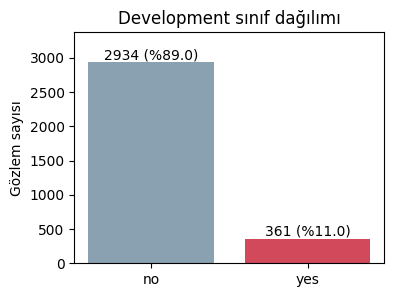

Kaydedildi: sekil2a_sinif_dagilimi.png


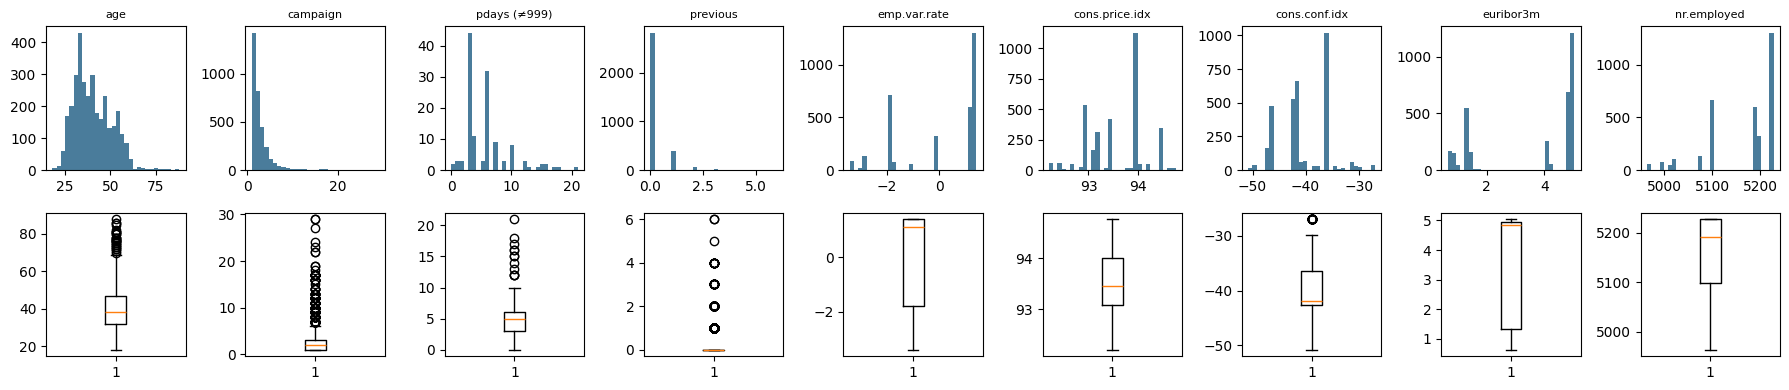

Kaydedildi: sekil2b_histogram_boxplot.png


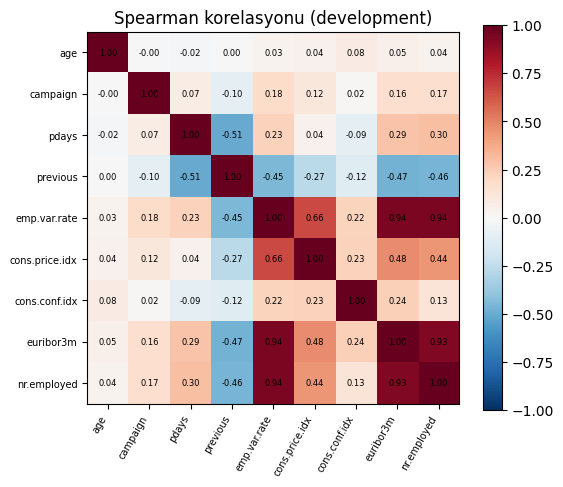

Kaydedildi: sekil2c_korelasyon.png


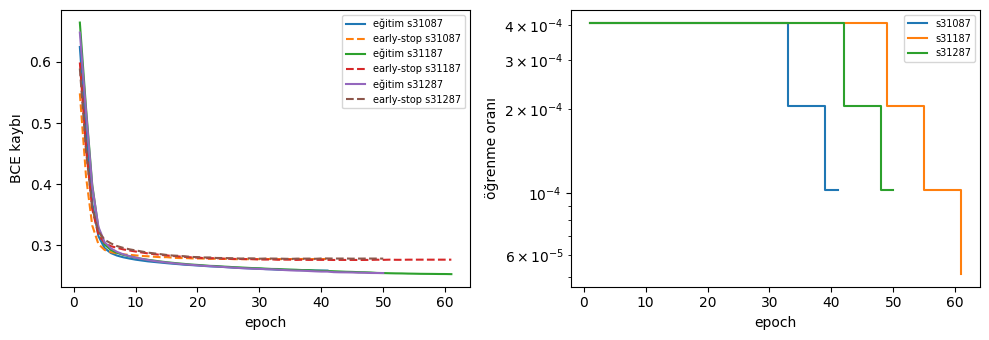

Kaydedildi: sekil4_egitim_egrileri.png


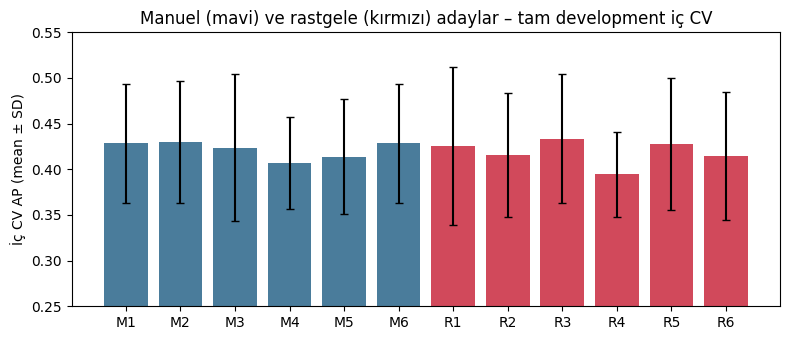

Kaydedildi: sekil5_manuel_vs_rastgele.png


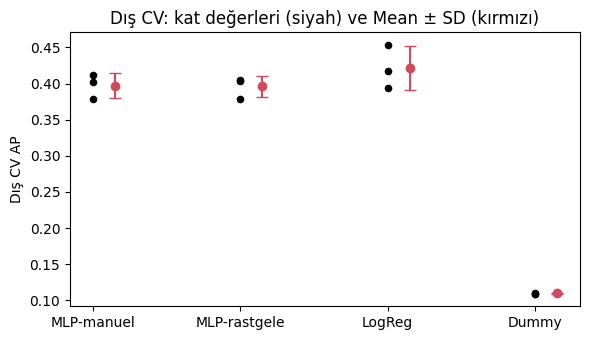

Kaydedildi: sekil5b_dis_cv.png


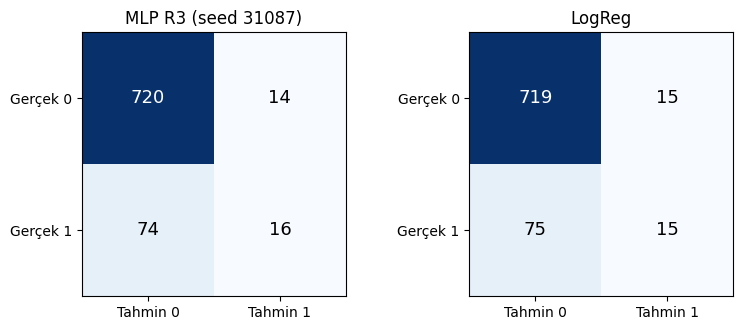

Kaydedildi: sekil6_confusion_matrix.png


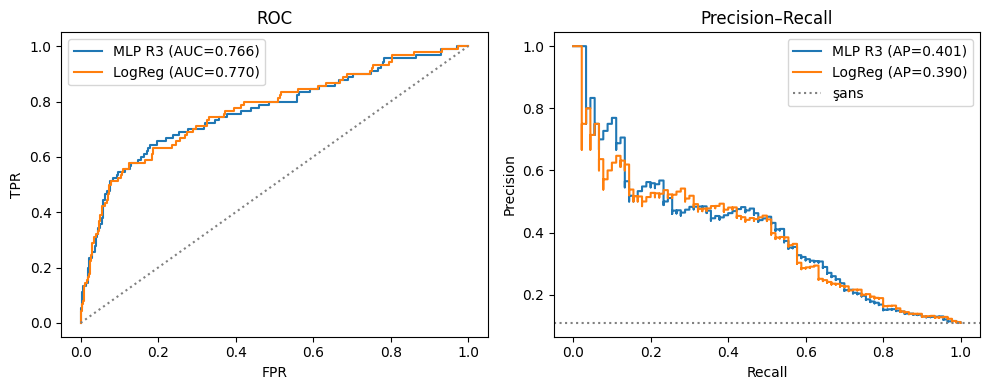

Kaydedildi: sekil7_roc_pr.png


In [35]:
# ===== Rapor şekilleri: hepsi KAYITLI dosyalardan üretilir (oturum sıfırlansa da çalışır) =====
import os, io, zipfile, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, roc_curve, precision_recall_curve,
                             roc_auc_score, average_precision_score)
from google.colab import drive
drive.mount("/content/drive")

KLASOR = "/content/drive/MyDrive/YSA_Vize_cikti"
RAPOR = f"{KLASOR}/rapor_icin"
os.makedirs(RAPOR, exist_ok=True)

# Veri dosyası yoksa resmi kaynaktan (UCI) indir
if not os.path.exists("bank-additional.csv"):
    dis_zip = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(
        "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip").read()))
    ic_zip = zipfile.ZipFile(io.BytesIO(dis_zip.read("bank-additional.zip")))
    open("bank-additional.csv", "wb").write(ic_zip.read("bank-additional/bank-additional.csv"))

def kaydet(fig, ad):
    fig.savefig(f"{RAPOR}/{ad}", dpi=200, bbox_inches="tight")   # ÖNCE kaydet
    plt.show()                                                    # sonra göster
    plt.close(fig)
    print("Kaydedildi:", ad)

ham = pd.read_csv("bank-additional.csv", sep=";")
bolunme = pd.read_csv(f"{KLASOR}/dataset_split.csv")
kilit = pd.read_csv(f"{KLASOR}/test_predictions_locked.csv")
ic = pd.read_csv(f"{KLASOR}/inner_cv_results.csv")
dis = pd.read_csv(f"{KLASOR}/outer_cv_results.csv")
y_test = (ham.loc[kilit["orig_index"], "y"] == "yes").astype(int).to_numpy()
dev_e = ham.loc[bolunme.loc[bolunme["set"] == "development", "orig_index"]]
ANA = 31087
num_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate",
            "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

# Şekil 2a: Sınıf dağılımı (development)
sayim = dev_e["y"].value_counts()
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(sayim.index, sayim.values, color=["#8aa1b1", "#d1495b"])
for i, v in enumerate(sayim.values):
    ax.text(i, v, f"{v} (%{100 * v / len(dev_e):.1f})", ha="center", va="bottom")
ax.set_ylabel("Gözlem sayısı"); ax.set_title("Development sınıf dağılımı"); ax.set_ylim(0, sayim.max() * 1.15)
kaydet(fig, "sekil2a_sinif_dagilimi.png")

# Şekil 2b: Sayısal özellikler – histogram ve boxplot (development)
fig, ax = plt.subplots(2, 9, figsize=(18, 4))
for i, c in enumerate(num_cols):
    s = dev_e[c] if c != "pdays" else dev_e.loc[dev_e["pdays"] != 999, c]
    ax[0, i].hist(s, bins=30, color="#4a7c9b"); ax[0, i].set_title(c + (" (≠999)" if c == "pdays" else ""), fontsize=8)
    ax[1, i].boxplot(s)
fig.tight_layout(); kaydet(fig, "sekil2b_histogram_boxplot.png")

# Şekil 2c: Spearman korelasyonu (development)
kor = dev_e[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols, fontsize=7)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{kor.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im); ax.set_title("Spearman korelasyonu (development)")
kaydet(fig, "sekil2c_korelasyon.png")

# Şekil 4: Nihai modelin eğitim eğrileri (3 seed)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for s in [31087, 31187, 31287]:
    g = pd.read_csv(f"{KLASOR}/history_seed{s}.csv")
    ax[0].plot(g.epoch, g.egitim_kaybi, label=f"eğitim s{s}")
    ax[0].plot(g.epoch, g.es_kaybi, "--", label=f"early-stop s{s}")
    ax[1].step(g.epoch, g.lr, where="post", label=f"s{s}")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("BCE kaybı"); ax[0].legend(fontsize=7)
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("öğrenme oranı"); ax[1].legend(fontsize=7)
fig.tight_layout(); kaydet(fig, "sekil4_egitim_egrileri.png")

# Şekil 5: Manuel vs rastgele (tam development iç CV, mean ± SD)
ozet = ic[ic.baglam == "tam_dev"].groupby("aday", sort=False)["AP"].agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(ozet.index, ozet["mean"], yerr=ozet["std"], capsize=3,
       color=["#4a7c9b" if k.startswith("M") else "#d1495b" for k in ozet.index])
ax.set_ylabel("İç CV AP (mean ± SD)"); ax.set_ylim(0.25, 0.55)
ax.set_title("Manuel (mavi) ve rastgele (kırmızı) adaylar – tam development iç CV")
fig.tight_layout(); kaydet(fig, "sekil5_manuel_vs_rastgele.png")

# Şekil 5b: Dış CV kat değerleri
fig, ax = plt.subplots(figsize=(6, 3.5))
modeller = ["MLP-manuel", "MLP-rastgele", "LogReg", "Dummy"]
for i, m in enumerate(modeller):
    v = dis[dis.model == m]["AP"].to_numpy()
    ax.scatter([i] * len(v), v, c="black", s=20)
    ax.errorbar(i + 0.15, v.mean(), v.std(ddof=1), fmt="o", c="#d1495b", capsize=4)
ax.set_xticks(range(4)); ax.set_xticklabels(modeller); ax.set_ylabel("Dış CV AP")
ax.set_title("Dış CV: kat değerleri (siyah) ve Mean ± SD (kırmızı)")
fig.tight_layout(); kaydet(fig, "sekil5b_dis_cv.png")

# Şekil 6: Confusion matrix (eşik 0,50)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
for a, (ad, sutun) in zip(ax, [(f"MLP R3 (seed {ANA})", f"mlp_pred_seed{ANA}"), ("LogReg", "logreg_pred")]):
    cm = confusion_matrix(y_test, kilit[sutun])
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["Tahmin 0", "Tahmin 1"])
    a.set_yticks([0, 1]); a.set_yticklabels(["Gerçek 0", "Gerçek 1"]); a.set_title(ad)
fig.tight_layout(); kaydet(fig, "sekil6_confusion_matrix.png")

# Şekil 7: ROC ve PR eğrileri
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for ad, sutun in [("MLP R3", f"mlp_prob_seed{ANA}"), ("LogReg", "logreg_prob")]:
    p = kilit[sutun]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{ad} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].step(rc, pr, where="post", label=f"{ad} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], ":", c="gray"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC")
ax[1].axhline(y_test.mean(), ls=":", c="gray", label="şans"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision–Recall"); ax[0].legend(); ax[1].legend()
fig.tight_layout(); kaydet(fig, "sekil7_roc_pr.png")

## Ortam bilgisi

In [36]:
# ===== Ortam bilgisi (README ve requirements.txt için) =====
import sys, platform, json, numpy, pandas, sklearn, scipy, matplotlib, torch
surumler = {"python": sys.version.split()[0], "numpy": numpy.__version__, "pandas": pandas.__version__,
            "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
            "torch": torch.__version__, "platform": platform.platform(), "islemci": platform.processor() or platform.machine(),
            "gpu": torch.cuda.is_available()}
print(json.dumps(surumler, indent=1))
json.dump(surumler, open("/content/drive/MyDrive/YSA_Vize_cikti/ortam_surumleri.json", "w"), indent=1)

{
 "python": "3.13.18",
 "numpy": "2.4.6",
 "pandas": "2.2.3",
 "scikit-learn": "1.6.1",
 "scipy": "1.16.3",
 "matplotlib": "3.10.0",
 "torch": "2.14.1+cpu",
 "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
 "islemci": "x86_64",
 "gpu": false
}
